# Signal Blackouts: Tracking a City Shuttle through GNSS Dropouts

## 1. Trajectory generation

In [34]:
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

In [35]:
# defining the constants
VARIANCE_A = 0.2**2
VARIANCE_ETA = 20**2
SIGMA_A = np.sqrt(VARIANCE_A)
SIGMA_ETA = np.sqrt(VARIANCE_ETA)

POINTS = 200
M_RUNS = 500
M_PRED = 7

T = 1
X_INIT = 5
V_INIT = 1

# probability of a measurement gap: the main case and the cases for comparison
P_GAP = 0.2
P_GAPS_COMPARE = [0.3, 0.5, 0.7]

# fixed seed, so that the plots and the numbers in the report do not change after re-running
np.random.seed(7)

steps = np.arange(POINTS * T, step = T)

True trajectory of the shuttle with the random acceleration $a_i$, $\sigma_a^2 = 0.2^2$:
$$x_i = x_{i-1} + V_{i-1}T + \frac{a_{i-1}T^2}{2}, \qquad V_i = V_{i-1} + a_{i-1}T$$
Measurements $z_i = x_i + \eta_i$, $\sigma_\eta^2 = 20^2$. At every step a random variable $\xi_i \sim U(0, 1)$ is generated, and if $\xi_i \le P$ the measurement is missing, $z_i = NaN$.

In [36]:
# a function to generate a true trajectory of the shuttle with the random acceleration a_i (from assignment 6)
def generate_true_trajectory(size=POINTS, init_coord=X_INIT, init_velocity=V_INIT, sigma_a=SIGMA_A, t=T):
    traj_points = np.zeros(size)
    velocity_points = np.zeros(size)
    traj_points[0] = init_coord
    velocity_points[0] = init_velocity

    for i in range(1, size):
        acceleration = np.random.normal(loc=0.0, scale=sigma_a)
        traj_points[i] = traj_points[i-1] + velocity_points[i-1] * t + acceleration * t**2 / 2
        velocity_points[i] = velocity_points[i-1] + acceleration * t

    return traj_points, velocity_points

# a function to generate measurements z_i = x_i + eta_i with gaps:
# the measurement is missing (NaN) if the random variable xi_i <= p_gap
def generate_measurements(true_trajectory, p_gap, sigma_eta=SIGMA_ETA):
    measurements = true_trajectory + np.random.normal(loc=0.0, scale=sigma_eta, size=true_trajectory.size)
    xi = np.random.uniform(0.0, 1.0, size=true_trajectory.size)
    measurements[xi <= p_gap] = np.nan
    return measurements

In [37]:
# the true trajectory is saved to a file, so that it can be reused;
# it is generated only if the file does not exist, so the saved trajectory is never overwritten
TRAJECTORY_FILE = Path("trajectory.csv")

if TRAJECTORY_FILE.exists():
    trajectory_data = np.loadtxt(TRAJECTORY_FILE, delimiter=",", skiprows=1)
    true_traj, true_vel = trajectory_data[:, 1], trajectory_data[:, 2]
else:
    true_traj, true_vel = generate_true_trajectory()
    np.savetxt(TRAJECTORY_FILE, np.column_stack((steps, true_traj, true_vel)),
               delimiter=",", header="time,x,V", comments="", fmt="%.17g")

## 2. Kalman filter algorithm with measurement gaps

In [38]:
# state-space model of the shuttle
PHI = np.array([[1, T],
                [0, 1]])

G = np.array([[T**2 / 2],
              [T]])

H = np.array([[1, 0]])

Q = G @ G.T * VARIANCE_A
R = np.array([[VARIANCE_ETA]])

# initial conditions
X_0_0 = np.array([[2],
                  [0]])
P_0_0 = np.array([[100, 0],
                  [0, 100]])

If the measurement $z_i$ is missing, there is no new information, so the filtration step is skipped:
$$X_{i,i} = X_{i,i-1}, \qquad P_{i,i} = P_{i,i-1}$$

In [39]:
# Kalman filter (from assignment 6) that works with measurement gaps
def kalman_filter(measurements, phi, h, q, r, x_0_0, p_0_0):
    size = measurements.size

    x_pred = np.zeros((size, 2, 1))   # predicted state X_{i,i-1}
    p_pred = np.zeros((size, 2, 2))   # prediction error covariance P_{i,i-1}
    x_filt = np.zeros((size, 2, 1))   # filtered state X_{i,i}
    p_filt = np.zeros((size, 2, 2))   # filtration error covariance P_{i,i}
    k = np.zeros((size, 2, 1))        # filter gain K_i

    identity = np.eye(2)
    x_prev = x_0_0
    p_prev = p_0_0

    for i in range(size):
        # prediction
        x_pred[i] = phi @ x_prev
        p_pred[i] = phi @ p_prev @ phi.T + q

        # filtration, only if the measurement is available
        if np.isnan(measurements[i]):
            x_filt[i] = x_pred[i]
            p_filt[i] = p_pred[i]
        else:
            k[i] = p_pred[i] @ h.T @ np.linalg.inv(h @ p_pred[i] @ h.T + r)
            x_filt[i] = x_pred[i] + k[i] * (measurements[i] - h @ x_pred[i])
            p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k

Prediction $m - 1 = 6$ steps ahead from every filtered estimate $X_{i,i}$. The state and the error covariance are extrapolated step by step without measurements:
$$X_{j+1,i} = \Phi X_{j,i}, \qquad P_{j+1,i} = \Phi P_{j,i} \Phi^T + Q, \qquad j = i, \dots, i + m - 2$$

In [40]:
# predictions m-1 steps ahead X_{i+m-1,i} and their error covariance matrices P_{i+m-1,i}
def predict_ahead(x_filt, p_filt, phi, q, steps_ahead=M_PRED - 1):
    x_pred_m = np.zeros_like(x_filt)
    p_pred_m = np.zeros_like(p_filt)

    for i in range(x_filt.shape[0]):
        x, p = x_filt[i], p_filt[i]
        for _ in range(steps_ahead):
            x = phi @ x
            p = phi @ p @ phi.T + q
        x_pred_m[i] = x
        p_pred_m[i] = p

    return x_pred_m, p_pred_m

In [41]:
# a function to shade the time steps where the measurement is missing
def shade_gaps(ax, measurements, step_size=T):
    for j, i in enumerate(np.where(np.isnan(measurements))[0]):
        ax.axvspan((i - 0.5) * step_size, (i + 0.5) * step_size, color="gray", alpha=0.2, linewidth=0,
                   label="Measurement gap" if j == 0 else None)

# a function to plot a true trajectory, measurements, the filtered estimate
# and the (m-1)-step ahead prediction (from assignment 8)
def plot_filter_results(true_traj, measurements, x_filt, x_pred_m, title, step_size=T):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    shift = M_PRED - 1
    fig, ax = plt.subplots(figsize=(12, 5))
    shade_gaps(ax, measurements, step_size)
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $x_i$")
    ax.scatter(steps, measurements, color="red", s=6, alpha=0.6, label="Measurements $z_i = x_i + \\eta_i$")
    ax.plot(steps, x_filt, color="blue", linewidth=1.5, label="Kalman Filter Estimate $x_{i,i}$")
    ax.plot(steps[shift:], x_pred_m[:-shift], color="purple", linewidth=1.2,
            label=f"Predicted estimate $x_{{i+{shift},i}}$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Coordinate x, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# a function to plot the filtered velocity and the calculated errors of one realization
def plot_velocity_and_calc_errors(true_vel, measurements, x_filt, p_filt, p_pred_m, title, step_size=T):
    steps = np.arange(true_vel.size * step_size, step = step_size)
    shift = M_PRED - 1
    fig, axes = plt.subplots(2, 1, figsize=(12, 9))

    axes[0].plot(steps, true_vel, color="green", linewidth=1.5, label="True velocity $V_i$")
    axes[0].plot(steps, x_filt[:, 1, 0], color="blue", linewidth=1.5, label="Filtered estimate $V_{i,i}$")
    axes[0].set_title(f"{title}: Velocity")
    axes[0].set_ylabel("Velocity V, m/s")

    axes[1].plot(steps, np.sqrt(p_filt[:, 0, 0]), color="blue", linewidth=1.5,
                 label="Calculated error $\\sigma_{x_{i,i}}$")
    axes[1].plot(steps[shift:], np.sqrt(p_pred_m[:-shift, 0, 0]), color="purple", linewidth=1.5,
                 label=f"Calculated error $\\sigma_{{x_{{i+{shift},i}}}}$")
    axes[1].axhline(SIGMA_ETA, color="red", linestyle="--", linewidth=1, label="Measurement error $\\sigma_\\eta$")
    axes[1].set_title(f"{title}: Calculated Errors of the Coordinate")
    axes[1].set_ylabel("Estimation error, m")

    for ax in axes:
        shade_gaps(ax, measurements, step_size)
        ax.set_xlabel("Time, s")
        ax.grid(True, color="black", linewidth=0.3)
        ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

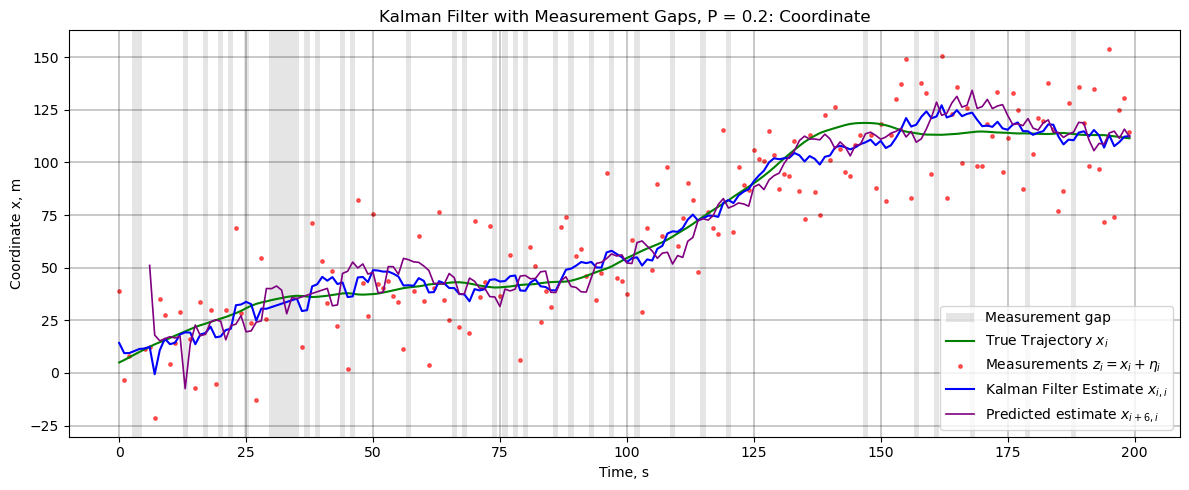

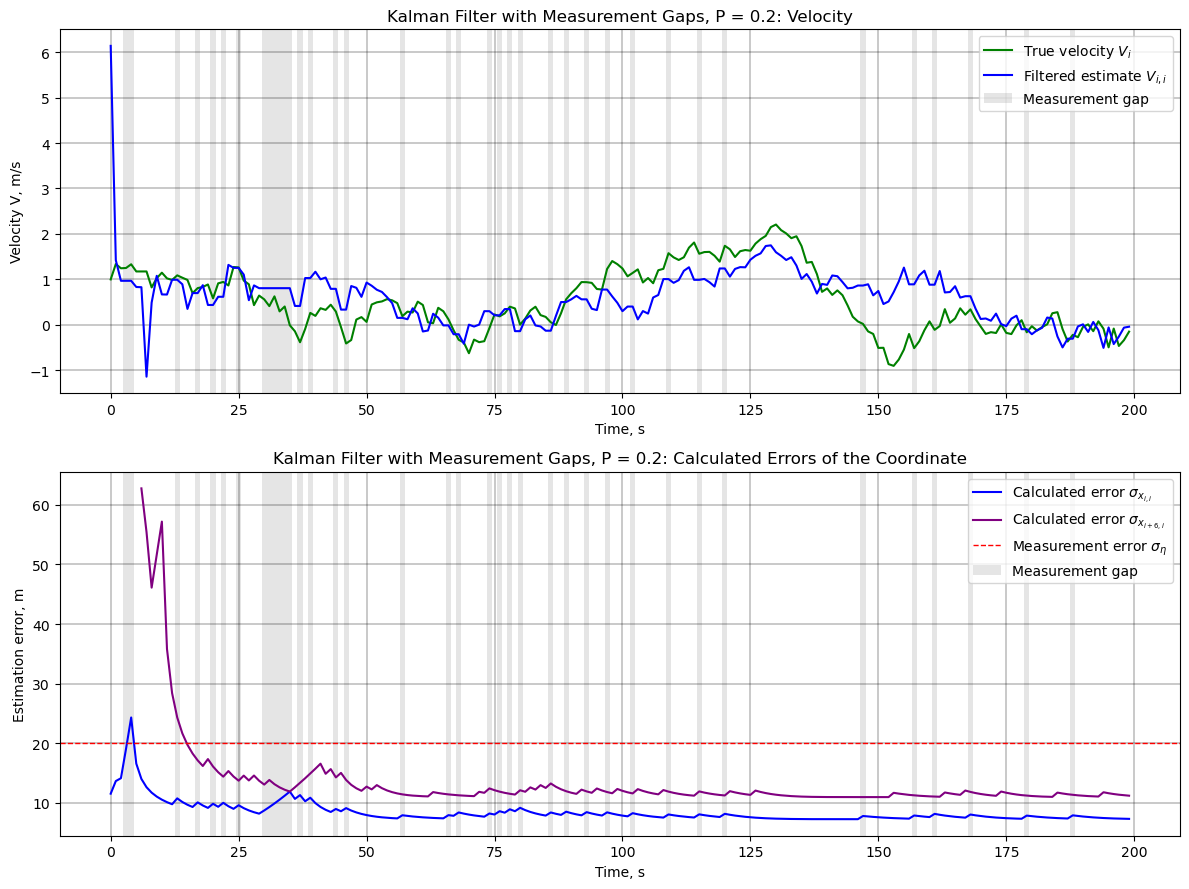

In [42]:
# one realization: the saved true trajectory, measurements with gaps, filtered estimates and 6-step ahead predictions
measurements = generate_measurements(true_traj, P_GAP)
x_pred, P_pred, x_filt, P_filt, K = kalman_filter(measurements, PHI, H, Q, R, X_0_0, P_0_0)
x_pred_m, P_pred_m = predict_ahead(x_filt, P_filt, PHI, Q)

plot_filter_results(true_traj, measurements, x_filt[:, 0, 0], x_pred_m[:, 0, 0],
                    f"Kalman Filter with Measurement Gaps, P = {P_GAP}: Coordinate")
plot_velocity_and_calc_errors(true_vel, measurements, x_filt, P_filt, P_pred_m,
                              f"Kalman Filter with Measurement Gaps, P = {P_GAP}")

## 3. Error estimation
True errors over $M = 500$ runs and calculated errors of the filtered estimate $x_{i,i}$, the 1-step ahead prediction $x_{i+1,i}$ and the 6-step ahead prediction $x_{i+6,i}$. The errors of the predictions are assigned to the time they refer to.

With gaps, the matrices $P$ depend on where the gaps are, so they are different in every run. Therefore the calculated error is also averaged over the runs: $\sigma_i = \sqrt{\frac{1}{M}\sum_{j=1}^{M} P^{(j)}_i}$.

In [43]:
# true and calculated errors of the filtered estimate, the 1-step and the (m-1)-step ahead predictions over M runs (from assignment 6)
def run_experiment(p_gap, m_runs=M_RUNS):
    shift = M_PRED - 1
    sq_err_filt = np.zeros((m_runs, POINTS))            # (x_i - x_{i,i})^2
    sq_err_pred1 = np.zeros((m_runs, POINTS))           # (x_i - x_{i,i-1})^2
    sq_err_pred_m = np.full((m_runs, POINTS), np.nan)   # (x_i - x_{i,i-m+1})^2
    var_filt = np.zeros((m_runs, POINTS))               # P_{i,i}[0, 0]
    var_pred1 = np.zeros((m_runs, POINTS))              # P_{i,i-1}[0, 0]
    var_pred_m = np.full((m_runs, POINTS), np.nan)      # P_{i,i-m+1}[0, 0]

    for run in range(m_runs):
        # new true trajectory and new measurements with new gaps in every run
        true_traj, _ = generate_true_trajectory()
        measurements = generate_measurements(true_traj, p_gap)
        x_pred, p_pred, x_filt, p_filt, _ = kalman_filter(measurements, PHI, H, Q, R, X_0_0, P_0_0)
        x_pred_m, p_pred_m = predict_ahead(x_filt, p_filt, PHI, Q)

        sq_err_filt[run] = (true_traj - x_filt[:, 0, 0])**2
        sq_err_pred1[run] = (true_traj - x_pred[:, 0, 0])**2
        sq_err_pred_m[run, shift:] = (true_traj[shift:] - x_pred_m[:-shift, 0, 0])**2

        var_filt[run] = p_filt[:, 0, 0]
        var_pred1[run] = p_pred[:, 0, 0]
        var_pred_m[run, shift:] = p_pred_m[:-shift, 0, 0]

    # true errors: root of the sum over runs divided by (M - 1), as in assignment 6
    true_err = [np.sqrt(np.sum(sq, axis=0) / (m_runs - 1)) for sq in (sq_err_filt, sq_err_pred1, sq_err_pred_m)]
    # calculated errors: root of the mean of P over runs
    calc_err = [np.sqrt(np.mean(var, axis=0)) for var in (var_filt, var_pred1, var_pred_m)]
    return true_err, calc_err

ESTIMATES = [("Filtered Estimate $x_{i,i}$", "$\\sigma_{x_{i,i}}$"),
             ("1-Step Ahead Prediction $x_{i+1,i}$", "$\\sigma_{x_{i+1,i}}$"),
             (f"{M_PRED - 1}-Step Ahead Prediction $x_{{i+{M_PRED - 1},i}}$", f"$\\sigma_{{x_{{i+{M_PRED - 1},i}}}}$")]

# a function to plot the true and calculated errors of the three estimates for one probability of gaps
def plot_true_vs_calc(true_err, calc_err, p_gap, start=2):
    fig, axes = plt.subplots(3, 1, figsize=(12, 13))
    for ax, true, calc, (name, calc_label) in zip(axes, true_err, calc_err, ESTIMATES):
        ax.plot(steps[start:], true[start:], color="blue", linewidth=1.5, label=f"True error ({M_RUNS} runs)")
        ax.plot(steps[start:], calc[start:], color="orange", linewidth=1.5, label=f"Calculated error {calc_label}")
        ax.axhline(SIGMA_ETA, color="red", linestyle="--", linewidth=1, label="Measurement error $\\sigma_\\eta$")
        ax.set_title(f"{name}: True and Calculated Errors, P = {p_gap}")
        ax.set_xlabel("Time, s")
        ax.set_ylabel("Estimation error, m")
        ax.grid(True, color="black", linewidth=0.3)
        ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

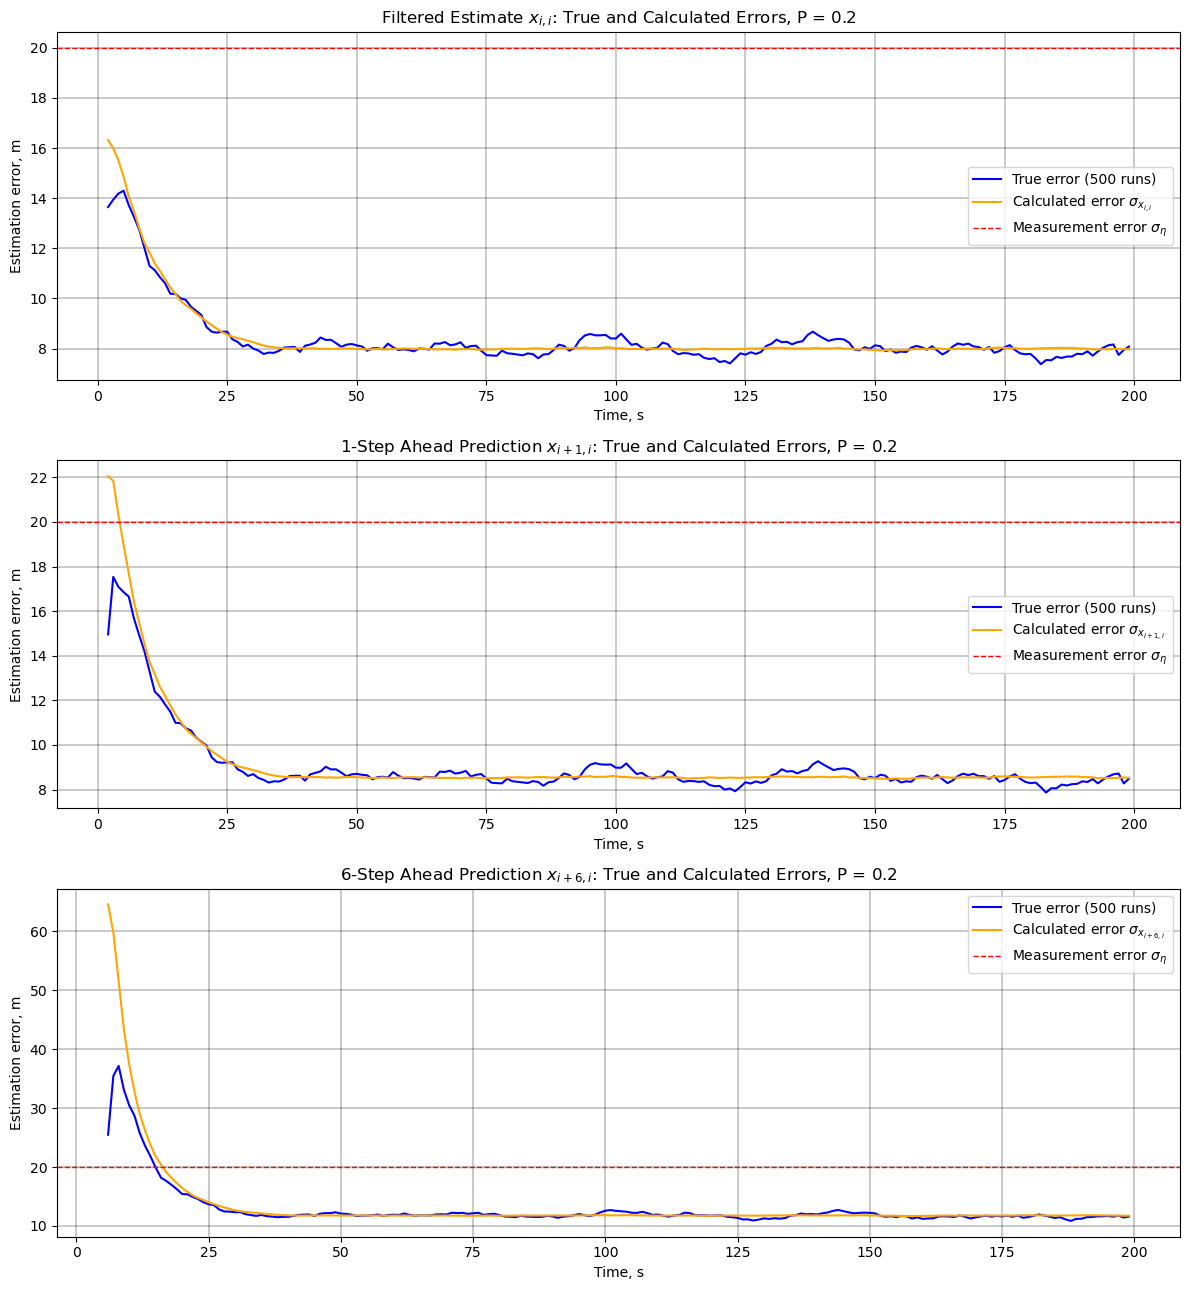

In [44]:
errors = {P_GAP: run_experiment(P_GAP)}
plot_true_vs_calc(*errors[P_GAP], P_GAP)

## Comparison for different probabilities of measurement gaps: P = 0.3, 0.5, 0.7

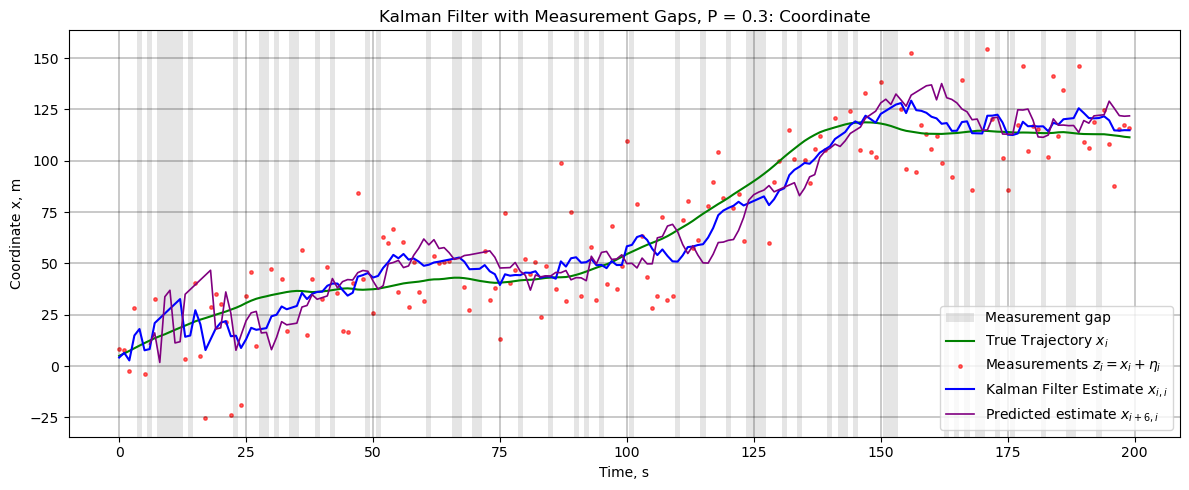

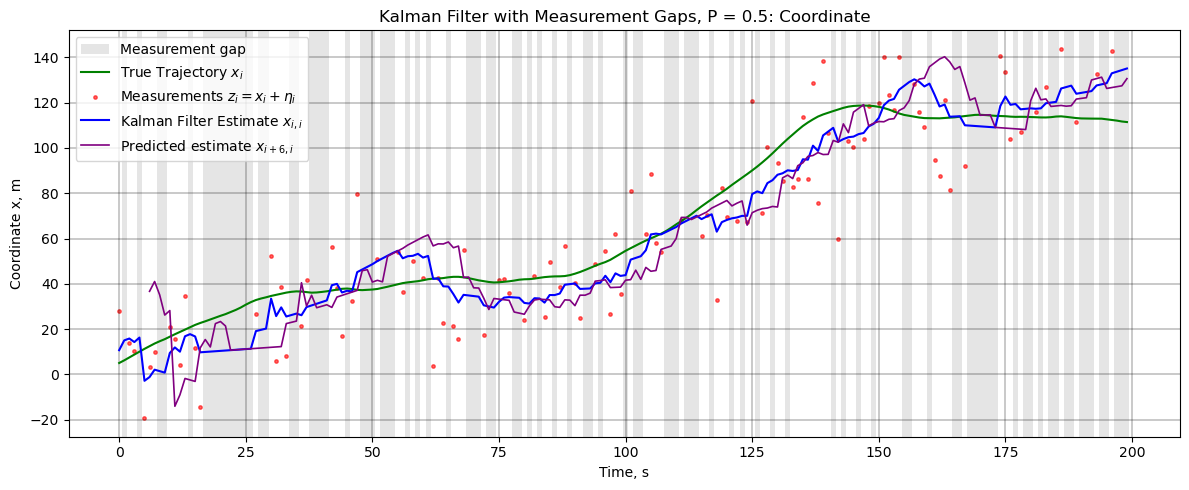

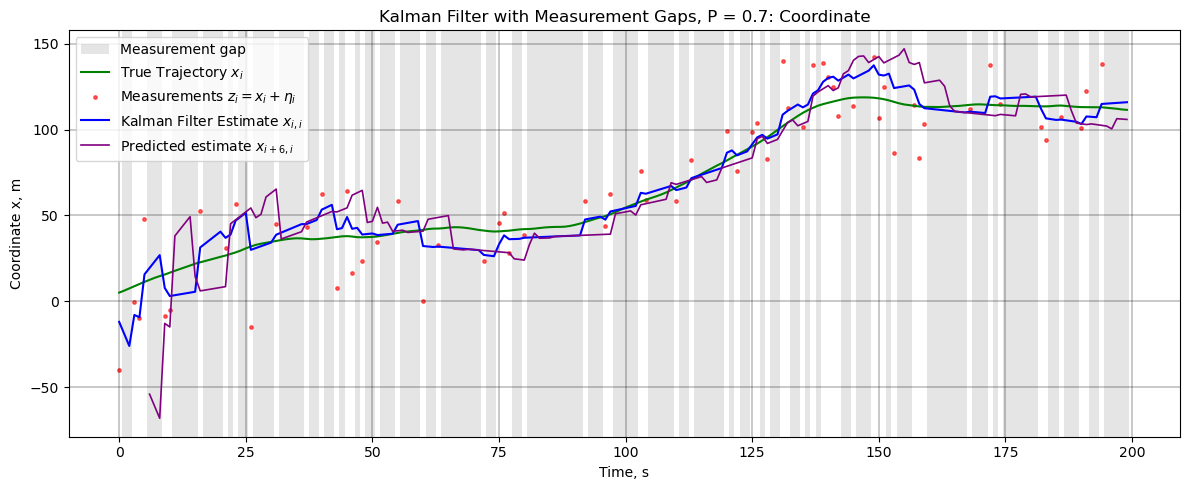

In [45]:
# the same true trajectory as above, new measurements with more frequent gaps
for p_gap in P_GAPS_COMPARE:
    measurements_p = generate_measurements(true_traj, p_gap)
    _, _, x_filt_p, P_filt_p, _ = kalman_filter(measurements_p, PHI, H, Q, R, X_0_0, P_0_0)
    x_pred_m_p, _ = predict_ahead(x_filt_p, P_filt_p, PHI, Q)
    plot_filter_results(true_traj, measurements_p, x_filt_p[:, 0, 0], x_pred_m_p[:, 0, 0],
                        f"Kalman Filter with Measurement Gaps, P = {p_gap}: Coordinate")

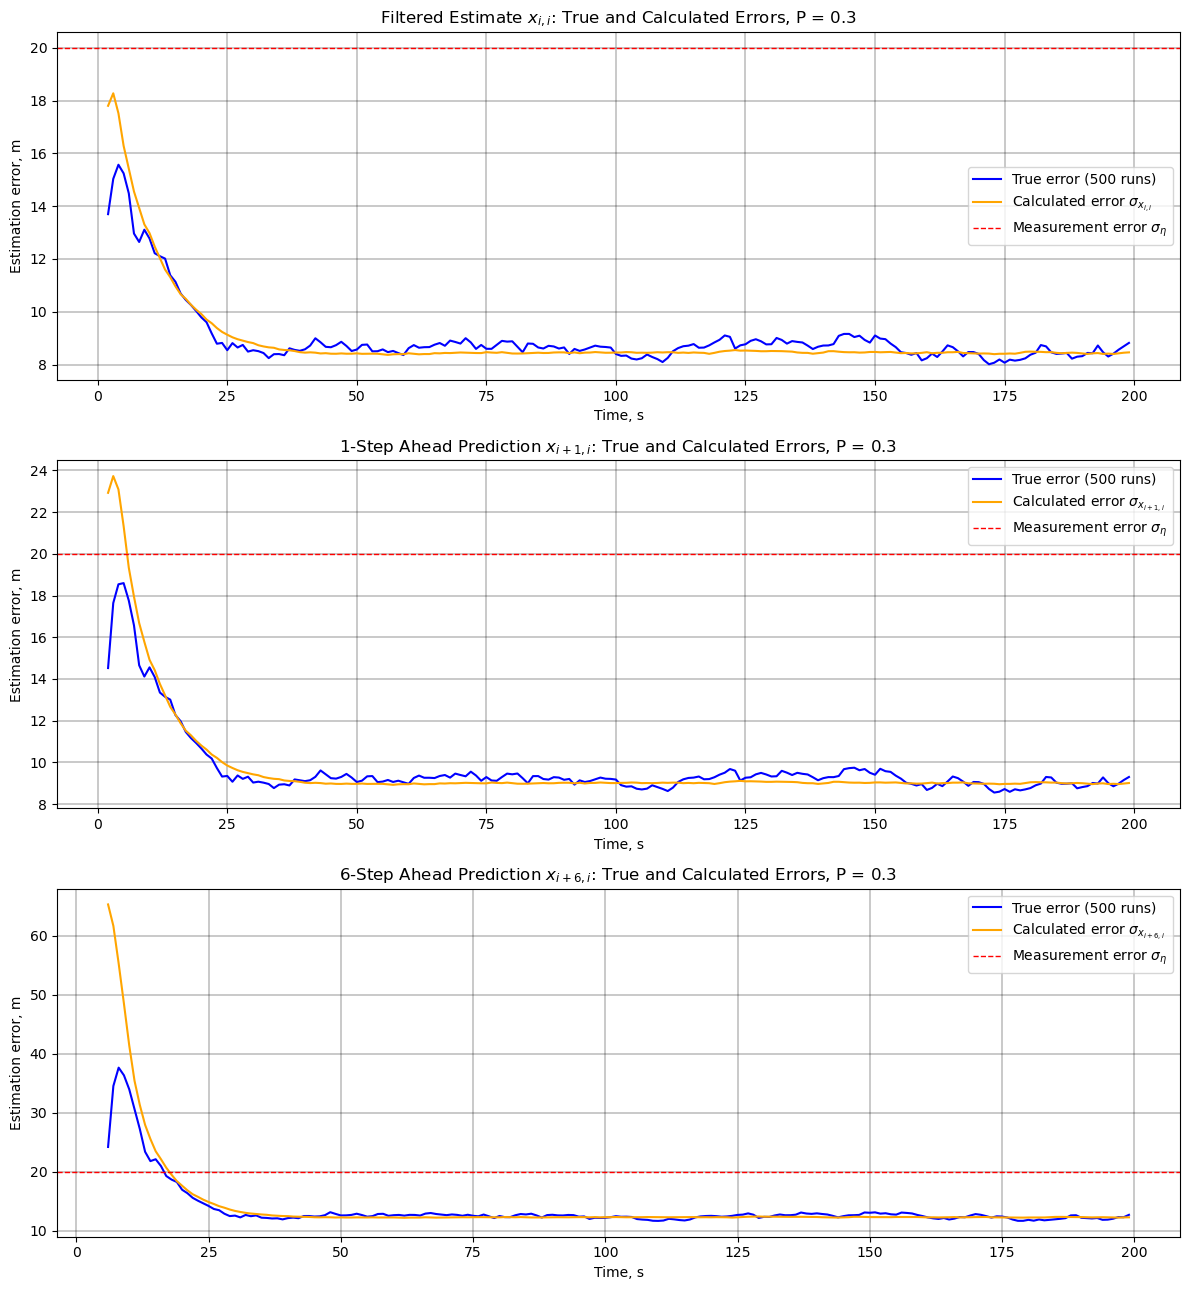

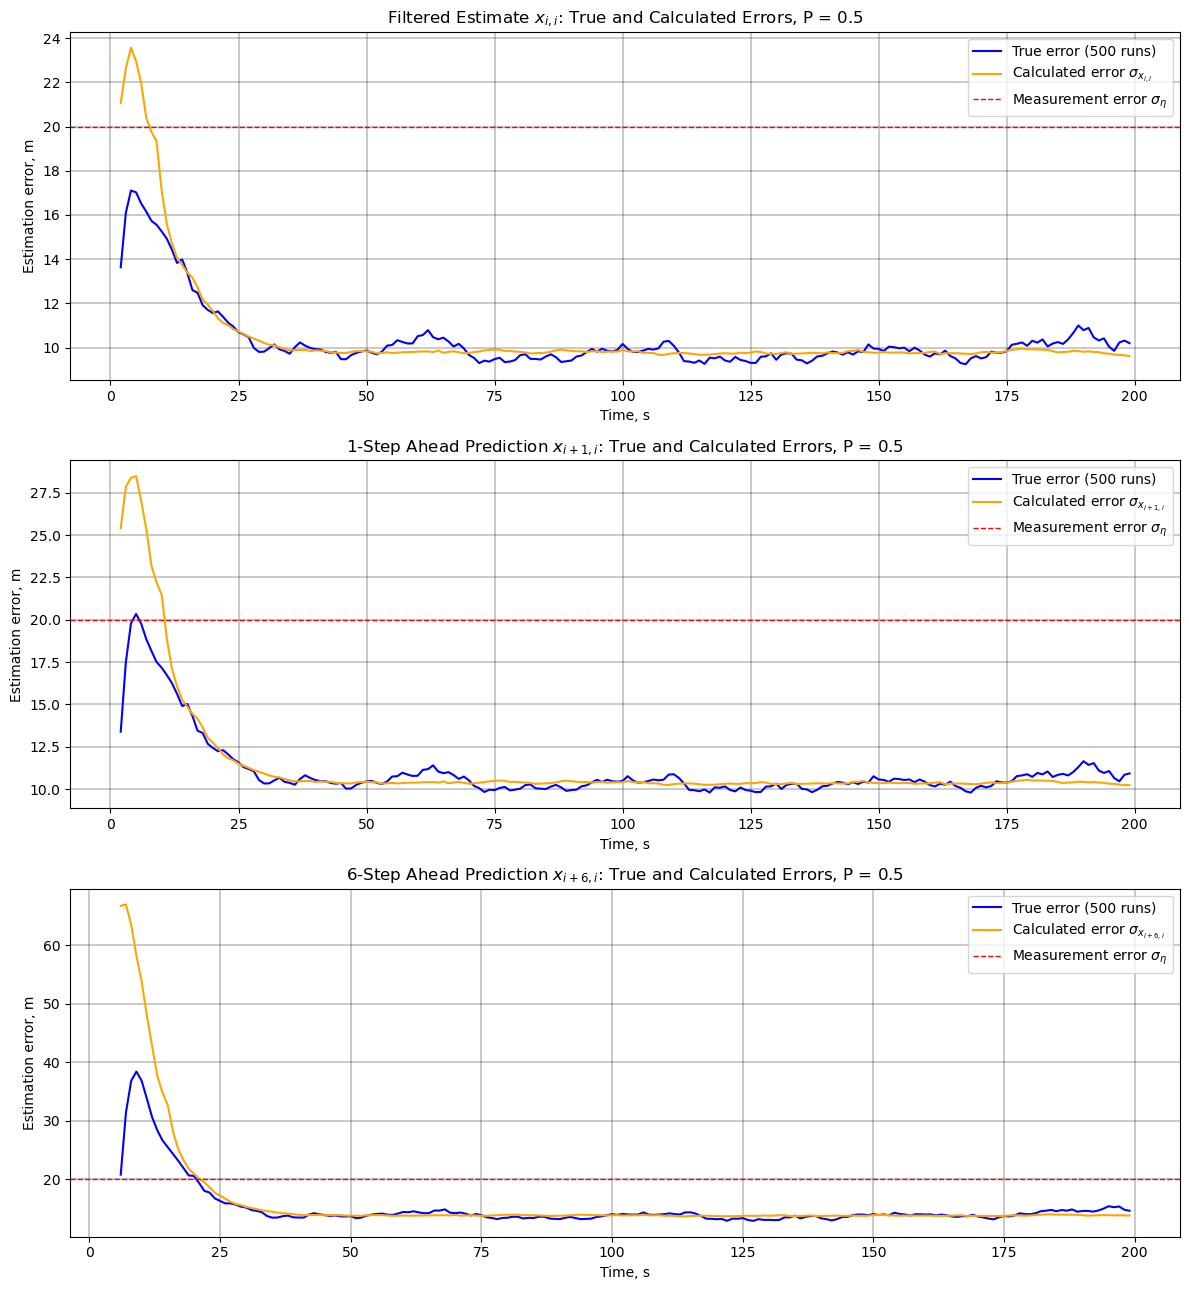

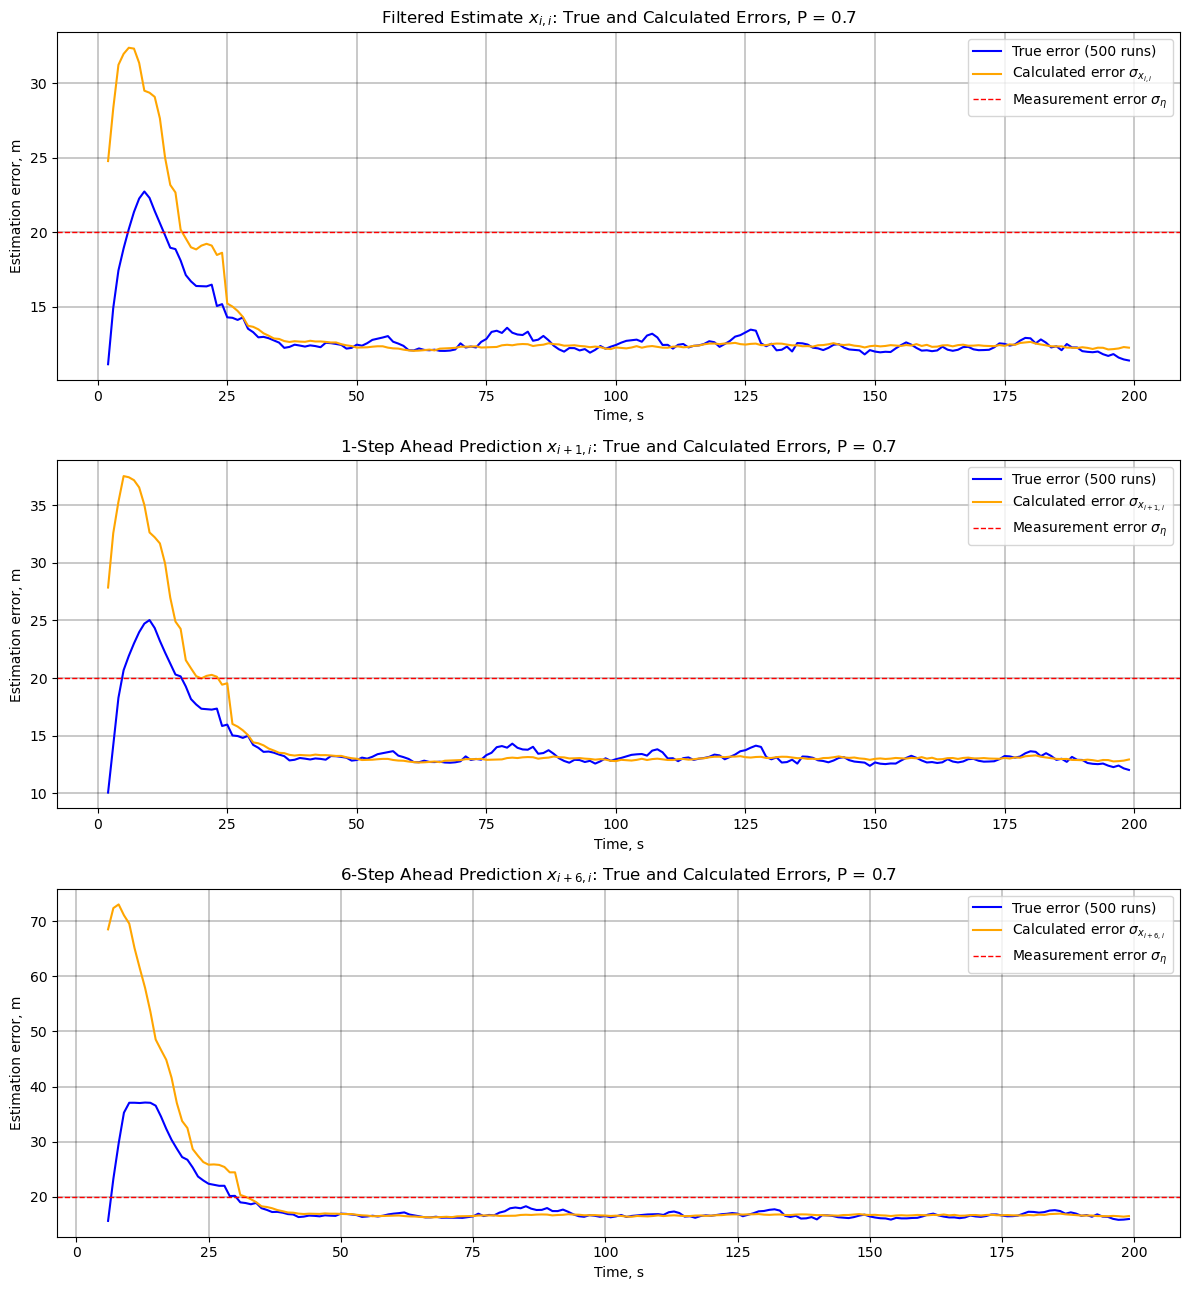

In [46]:
for p_gap in P_GAPS_COMPARE:
    errors[p_gap] = run_experiment(p_gap)
    plot_true_vs_calc(*errors[p_gap], p_gap)

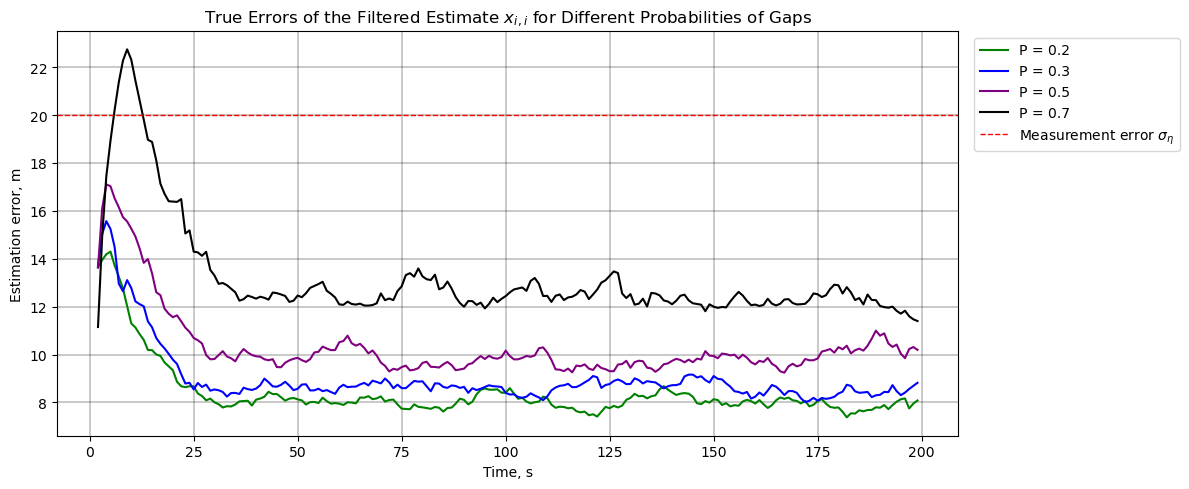

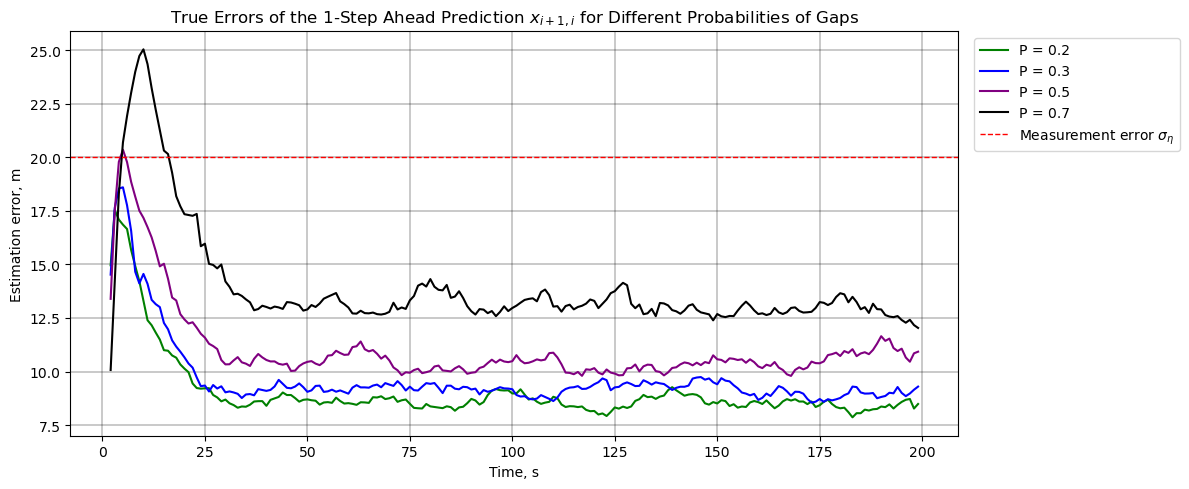

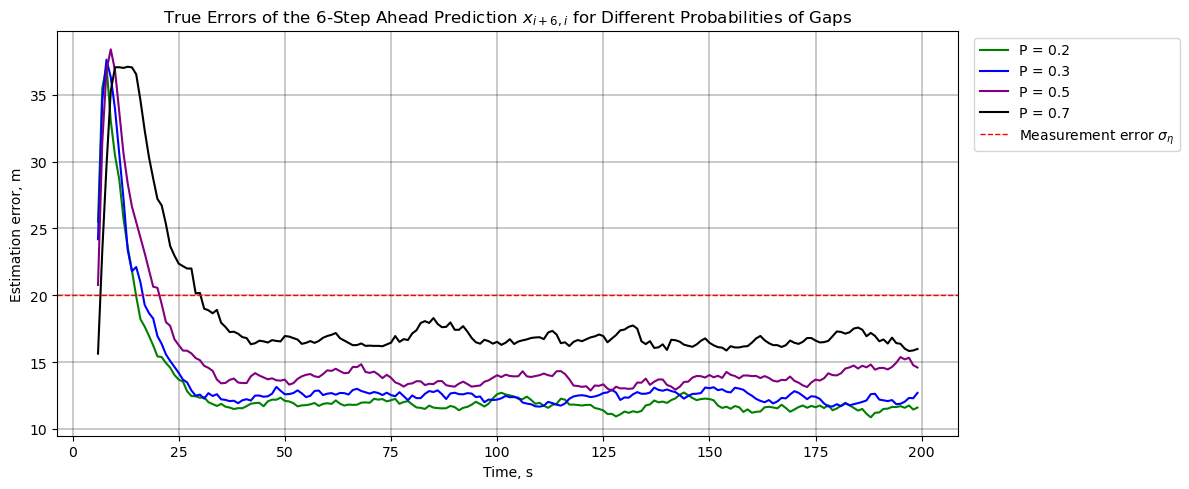

In [47]:
# a function to plot several error curves on one figure (from assignment 8)
def plot_errors(curves, title, step_size=T, start=2, sigma_eta=None, ylabel="Estimation error, m", legend_outside=False):
    # curves: list of (values, label, color)
    steps = np.arange(len(curves[0][0]) * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    for values, label, color in curves:
        ax.plot(steps[start:], values[start:], color=color, linewidth=1.5, label=label)
    if sigma_eta is not None:
        ax.axhline(sigma_eta, color="red", linestyle="--", linewidth=1, label="Measurement error $\\sigma_\\eta$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel(ylabel)
    ax.grid(True, color="black", linewidth=0.3)
    # many curves: the legend is placed to the right of the plot so that it does not cover them
    if legend_outside:
        ax.legend(frameon=True, loc="upper left", bbox_to_anchor=(1.01, 1))
    else:
        ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# true errors of every estimate for all probabilities of gaps
colors = {0.2: "green", 0.3: "blue", 0.5: "purple", 0.7: "black"}
for j, (name, _) in enumerate(ESTIMATES):
    plot_errors([(errors[p_gap][0][j], f"P = {p_gap}", colors[p_gap]) for p_gap in errors],
                f"True Errors of the {name} for Different Probabilities of Gaps",
                sigma_eta=SIGMA_ETA, legend_outside=True)

In [48]:
# summary table of the steady-state errors: mean over the last 100 steps
names = ["filtered", "1-step", f"{M_PRED - 1}-step"]
print(f"{'P':<6}" + "".join(f"{name + ' true, m':>18}{name + ' calc, m':>18}" for name in names))
for p_gap, (true_err, calc_err) in errors.items():
    print(f"{p_gap:<6}" + "".join(f"{np.mean(true[-100:]):>18.2f}{np.mean(calc[-100:]):>18.2f}"
                                  for true, calc in zip(true_err, calc_err)))

P       filtered true, m  filtered calc, m    1-step true, m    1-step calc, m    6-step true, m    6-step calc, m
0.2                 7.98              7.99              8.53              8.54             11.74             11.78
0.3                 8.58              8.46              9.13              9.02             12.37             12.30
0.5                 9.84              9.77             10.43             10.36             13.86             13.77
0.7                12.36             12.39             13.00             13.03             16.62             16.66
